In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dense, Flatten, BatchNormalization, Conv2D, MaxPool2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix
import itertools
import os
import shutil
import random
import glob
import matplotlib.pyplot as plt
import warnings
import pandas as pd
warnings.simplefilter(action='ignore', category=FutureWarning)
%matplotlib inline

In [ ]:
train_path = ""
train_df = pd.read_csv(os.path.join(train_path, "Train.csv"))
test_df = pd.read_csv(os.path.join(train_path, "Test.csv"))

print(train_df.head())
print(test_df.head())

   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0     27      26       5       5      22      20       20   
1     28      27       5       6      23      22       20   
2     29      26       6       5      24      21       20   
3     28      27       5       6      23      22       20   
4     28      26       5       5      23      21       20   

                             Path  
0  Train/20/00020_00000_00000.png  
1  Train/20/00020_00000_00001.png  
2  Train/20/00020_00000_00002.png  
3  Train/20/00020_00000_00003.png  
4  Train/20/00020_00000_00004.png  
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId            Path
0     53      54       6       5      48      49       16  Test/00000.png
1     42      45       5       5      36      40        1  Test/00001.png
2     48      52       6       6      43      47       38  Test/00002.png
3     27      29       5       5      22      24       33  Test/00003.png
4     60      57       5       5      55      5

# Pre processing and using ImageDataGenerator for image preparation

In [4]:
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.vgg16.preprocess_input,
    validation_split=0.25
)

# Training batches
train_batches = datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=train_path,
    x_col="Path",
    y_col="ClassId",
    target_size=(64, 64),
    class_mode="raw",
    batch_size=64,
    subset="training",
    seed=42
)

# Validation batches
valid_batches = datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=train_path,
    x_col="Path",
    y_col="ClassId",
    target_size=(64, 64),
    class_mode="raw",
    batch_size=64,
    subset="validation",
    seed=42
)

# Test batches
test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.vgg16.preprocess_input
)

test_batches = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    directory=train_path,
    x_col="Path",
    y_col="ClassId",
    target_size=(64, 64),
    class_mode="raw",
    batch_size=64,
    shuffle=False
)

Found 29407 validated image filenames.
Found 9802 validated image filenames.
Found 12630 validated image filenames.


In [5]:
# image showing
imgs, labels = next(train_batches)

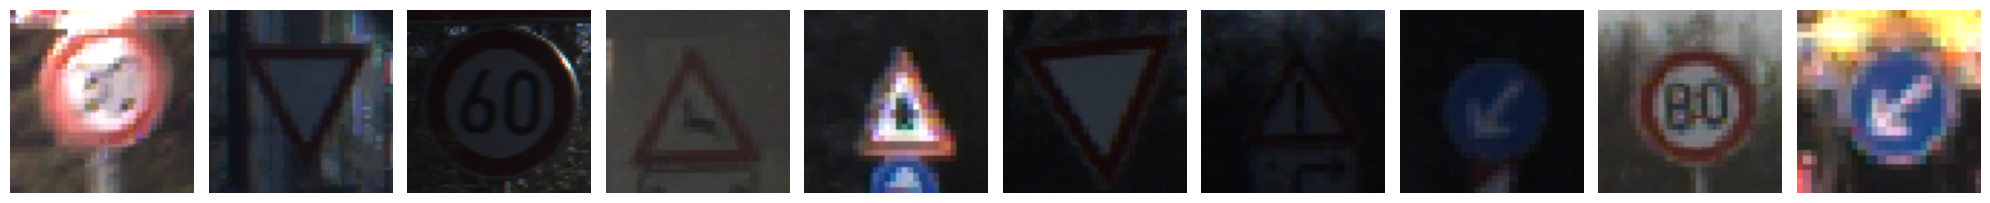

[ 1 13  3 31 11 13 18 39  5 39 41 14 33  5 12 22 35  1 15 10 20 13 18 18
 35  5 13 12 28 12 11  5 32 18  5  1 15 17  4 35 12 20 11  2 11 18 20  1
 18  2 38 30 10 18 10  5 18 38 18 11  5 26 23 15]


In [6]:
def plotImages(images_arr):
    fig, axes = plt.subplots(1, 10, figsize=(20, 5))
    axes = axes.flatten()

    for img, ax in zip(images_arr, axes):
        # Reverse VGG16 preprocessing for display
        img = img + [103.939, 116.779, 123.68]
        img = img[..., ::-1]  # BGR to RGB

        img = img.clip(0, 255).astype("uint8")

        ax.imshow(img)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

plotImages(imgs)
print(labels)

# Training and fitting

In [7]:
from tensorflow.keras.layers import Dropout, GlobalAveragePooling2D

# previous model
# model = Sequential([
#     Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding = 'same', input_shape=(64,64,3)),
#     MaxPool2D(pool_size=(2, 2), strides=2),
#     Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding = 'same'),
#     MaxPool2D(pool_size=(2, 2), strides=2),
#     Flatten(),
#     Dense(units=43, activation='softmax')
# ])


#new implementation - 
model = Sequential([
    # input + augmentation
    tf.keras.Input(shape=(64, 64, 3)),                  
    tf.keras.layers.RandomRotation(0.05),               
    tf.keras.layers.RandomZoom(0.1),                    
    tf.keras.layers.RandomTranslation(0.1, 0.1),

    # Simple features - Layer 1
    Conv2D(32, 3, activation='relu', padding='same'),   
    BatchNormalization(),                               
    Conv2D(32, 3, activation='relu', padding='same'),   
    MaxPool2D(2),                                       
    Dropout(0.25), 

    # More complex features - Layer 2
    Conv2D(64, 3, activation='relu', padding='same'),   
    BatchNormalization(),
    Conv2D(64, 3, activation='relu', padding='same'),
    MaxPool2D(2),                                     
    Dropout(0.25),

    # high level features - Layer 3
    Conv2D(128, 3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPool2D(2),                                       
    Dropout(0.25),

    # final output
    GlobalAveragePooling2D(),                          
                                                       
    Dropout(0.25),                              
    Dense(43, activation='softmax') 
])

I0000 00:00:1793177044.099371      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793177044.103208      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [8]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# instead of running epochs manually, earlystopping is introduced to stop in more number of epochs
# taking 30 here
# sample down here 💀
# model.fit(x=train_batches,
#     steps_per_epoch=len(train_batches),
#     validation_data=valid_batches,
#     validation_steps=len(valid_batches),
#     epochs=30,
#     verbose=2
# )

# using call backs
history = model.fit(
    x=train_batches,
    validation_data=valid_batches,
    epochs=30,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    ],
    verbose=2
)

Epoch 1/30
460/460 - 644s - 1s/step - accuracy: 0.6124 - loss: 1.3823 - val_accuracy: 0.7565 - val_loss: 1.1606 - learning_rate: 0.0010
Epoch 2/30
460/460 - 45s - 99ms/step - accuracy: 0.8230 - loss: 0.6844 - val_accuracy: 0.9349 - val_loss: 0.3817 - learning_rate: 0.0010
Epoch 3/30
460/460 - 46s - 100ms/step - accuracy: 0.9132 - loss: 0.3701 - val_accuracy: 0.9636 - val_loss: 0.2240 - learning_rate: 0.0010
Epoch 4/30
460/460 - 46s - 101ms/step - accuracy: 0.9501 - loss: 0.2254 - val_accuracy: 0.9790 - val_loss: 0.1498 - learning_rate: 0.0010
Epoch 5/30
460/460 - 46s - 100ms/step - accuracy: 0.9644 - loss: 0.1572 - val_accuracy: 0.9922 - val_loss: 0.0758 - learning_rate: 0.0010
Epoch 6/30
460/460 - 46s - 101ms/step - accuracy: 0.9671 - loss: 0.1331 - val_accuracy: 0.9866 - val_loss: 0.0770 - learning_rate: 0.0010
Epoch 7/30
460/460 - 46s - 100ms/step - accuracy: 0.9754 - loss: 0.1005 - val_accuracy: 0.9890 - val_loss: 0.0576 - learning_rate: 0.0010
Epoch 8/30
460/460 - 47s - 101ms/step

In [12]:
print("Training images:", train_batches.samples)
print("Validation images:", valid_batches.samples)
print("Batch size:", train_batches.batch_size)
print("Training steps:", len(train_batches))
print("Validation steps:", len(valid_batches))

Training images: 29407
Validation images: 9802
Batch size: 64
Training steps: 460
Validation steps: 154


In [13]:
print("Samples:", test_batches.samples)
print("Batch size:", test_batches.batch_size)
print("Image size:", test_batches.image_shape)
print("Batches:", len(test_batches))

Samples: 12630
Batch size: 64
Image size: (64, 64, 3)
Batches: 198


In [14]:
#model.evaluate(test_batches, verbose=2)
test_batches.reset()

results = model.evaluate(test_batches, verbose=1)
print(results)

198/198 ━━━━━━━━━━━━━━━━━━━━ 569s 3s/step - accuracy: 0.9802 - loss: 0.0701
[0.070076122879982, 0.9802058339118958]


In [ ]:
model.save("gtsrb_cnn.keras")

# Save the trained model to drive

In [ ]:
model.save('/content/drive/MyDrive/traffic_sign_model.keras')

print("Model saved successfully!")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_path = '/content/drive/MyDrive/traffic_sign_model.tflite'

with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

# TFlite processing

In [ ]:

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT] 
tflite_model = converter.convert()

with open("/Models/gtsrb.tflite", "wb") as f:
    f.write(tflite_model)

print(len(tflite_model) / 1024, "KB")

INFO:tensorflow:Assets written to: /tmp/tmporhv39f1/assets


INFO:tensorflow:Assets written to: /tmp/tmporhv39f1/assets


Saved artifact at '/tmp/tmporhv39f1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 43), dtype=tf.float32, name=None)
Captures:
  134307575406928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561617936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561617552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561617360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561615632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561617744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561618128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561619088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561618704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561617168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134307561618320

W0000 00:00:1793181613.403630      49 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793181613.403676      49 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793181613.422323      49 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
